# 13 · Portfolio Rates & Macroeconomic Links (`13_economy_links.py`)

Mortgage defaults and prepayments do not move in isolation—they respond with clear timing delays to unemployment spikes, house-price drops, and policy rate shifts. In this notebook we verify `m2.portfolio_rates_quarterly_mart`, `m2.economy_correlations_mart`, and `m2.macro_downturn_mart` read-only from our sample database, inspecting peak national economic moves and how correlation strength shifts across publication lags from 0 to 24 months.

<div style="background:#FFFFFF; border:1px solid #E5E7EB; border-radius:10px; padding:14px; margin:8px 0;">
<div style="font-family:Segoe UI,Arial,sans-serif; font-size:13px; font-weight:700; color:#051C2C; margin-bottom:8px;">Macroeconomic Linkage & Publication-Lag Check</div>
<svg viewBox="0 0 920 110" width="100%" xmlns="http://www.w3.org/2000/svg">
<defs><marker id="arr" viewBox="0 0 10 10" refX="8" refY="5" markerWidth="6" markerHeight="6" orient="auto-start-reverse"><path d="M 0 1 L 10 5 L 0 9 z" fill="#2251FF"/></marker></defs>
<rect x="20" y="18" width="170" height="68" rx="8" fill="#051C2C" stroke="#051C2C" stroke-width="1.5"/>
<text x="105.0" y="46" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="12" font-weight="700" fill="#FFFFFF">Quarterly Portfolio KPIs</text>
<text x="105.0" y="66" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="10.5" fill="#CBD5E1">DR, CPR, Cure, Severity</text>
<line x1="194" y1="52" x2="252" y2="52" stroke="#2251FF" stroke-width="2" marker-end="url(#arr)"/>
<rect x="256" y="18" width="170" height="68" rx="8" fill="#F8FAFC" stroke="#2251FF" stroke-width="1.5"/>
<text x="341.0" y="46" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="12" font-weight="700" fill="#051C2C">Macro Merge (No Leakage)</text>
<text x="341.0" y="66" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="10.5" fill="#475569">FRED unrate, rates & FHFA HPI</text>
<line x1="430" y1="52" x2="488" y2="52" stroke="#2251FF" stroke-width="2" marker-end="url(#arr)"/>
<rect x="492" y="18" width="170" height="68" rx="8" fill="#F8FAFC" stroke="#2251FF" stroke-width="1.5"/>
<text x="577.0" y="46" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="12" font-weight="700" fill="#051C2C">Downturn Timing</text>
<text x="577.0" y="66" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="10.5" fill="#475569">m2.macro_downturn_mart</text>
<line x1="666" y1="52" x2="724" y2="52" stroke="#2251FF" stroke-width="2" marker-end="url(#arr)"/>
<rect x="728" y="18" width="170" height="68" rx="8" fill="#2251FF" stroke="#2251FF" stroke-width="1.5"/>
<text x="813.0" y="46" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="12" font-weight="700" fill="#FFFFFF">0-24m Lag Grid</text>
<text x="813.0" y="66" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="10.5" fill="#CBD5E1">m2.economy_correlations_mart</text>
</svg></div>

First we open our read-only connection and inspect `m2.macro_downturn_mart` plus recent rows of `m2.portfolio_rates_quarterly_mart` for `segment = 'ALL'`.

In [1]:
# Load path, DuckDB, pandas, I/O, and inline chart display utilities
# Import standard libraries to inspect saved marts read-only and render 300 dpi figures inline
import io
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import Image, display

# Locate residential_mortgage/ root and attach module2_sample.duckdb strictly READ_ONLY
# Walk upward until reaching residential_mortgage/, then open an in-memory DuckDB connection
PACKAGE_ROOT = Path.cwd()
while PACKAGE_ROOT.name != "residential_mortgage" and PACKAGE_ROOT != PACKAGE_ROOT.parent:
    PACKAGE_ROOT = PACKAGE_ROOT.parent
if PACKAGE_ROOT.name != "residential_mortgage":
    PACKAGE_ROOT = Path(r"E:\Repos\V4_bank-credit-risk-platform\residential_mortgage")

FIXED_M2_DB = PACKAGE_ROOT / "00_data/processed/module_outputs/02_portfolio_analytics/sample/module2_sample.duckdb"
con = duckdb.connect(":memory:")
con.execute(f"ATTACH '{FIXED_M2_DB.as_posix()}' AS m2 (READ_ONLY)")

# Inspect national macro peak-to-trough swings recorded in macro_downturn_mart
# Query national unemployment rise and FHFA HPI peak-to-trough drop from m2.macro_downturn_mart
display(con.execute("SELECT * FROM m2.macro_downturn_mart ORDER BY indicator").fetchdf())

# Preview recent quarterly portfolio performance rates alongside linked macro indicators
# Query m2.portfolio_rates_quarterly_mart filtered to whole portfolio ('ALL')
con.execute("""
    SELECT quarter_date, round(default_rate_ann * 100, 2) AS dr_ann_pct,
           round(cure_rate_qtr * 100, 2) AS cure_qtr_pct,
           round(cpr_qtr * 100, 2) AS cpr_qtr_pct,
           round(unrate_pct, 2) AS unrate_pct,
           round(nat_hpi_chg_12m_pct, 2) AS nat_hpi_12m_pct
    FROM m2.portfolio_rates_quarterly_mart
    WHERE segment = 'ALL'
    ORDER BY quarter_date DESC
    LIMIT 8
""").fetchdf()

,geography,indicator,peak_date,trough_date,move_magnitude
0,US_NATIONAL,national_hpi_fall_pct,2007-04-01,2011-05-01,21.294605
1,US_NATIONAL,unemployment_rate_rise_pp,2019-09-01,2020-04-01,11.300000


,quarter_date,dr_ann_pct,cure_qtr_pct,cpr_qtr_pct,unrate_pct,nat_hpi_12m_pct
0,2025-10-01,0.94,9.91,7.10,4.45,2.21
1,2025-07-01,0.85,19.03,6.44,4.23,2.89
2,2025-04-01,0.42,11.53,6.60,4.23,3.75
3,2025-01-01,0.42,13.62,4.58,4.10,4.88
4,2024-10-01,0.59,11.99,6.28,4.13,4.49
5,2024-07-01,0.34,16.00,5.63,4.17,5.19
6,2024-04-01,0.77,9.83,5.25,3.90,6.50
7,2024-01-01,0.60,10.08,4.43,3.80,6.37


Next we verify the script's exact `[0, 24]` month publication-lag contract on `m2.economy_correlations_mart` and identify which lag maximizes correlation with annualized default rates for each macro indicator.

In [2]:
# Verify exact 3-month lag spacing [0..24] and inspect peak correlation per macro series
# Check set equality against {0,3,6,9,12,15,18,21,24} and query strongest lag for default_rate_ann
lags = {r[0] for r in con.execute("SELECT DISTINCT lag_months FROM m2.economy_correlations_mart").fetchall()}
assert lags == {0, 3, 6, 9, 12, 15, 18, 21, 24}, f"Unexpected lags: {lags}"
print(f"PASS  publication lag grid verified: {sorted(lags)}")

con.execute("""
    SELECT series_name,
           arg_max(lag_months, abs(pearson_corr)) AS strongest_lag_m,
           round(arg_max(pearson_corr, abs(pearson_corr)), 3) AS strongest_corr,
           max(n_quarters) AS quarters_used
    FROM m2.economy_correlations_mart
    WHERE rate_name = 'default_rate_ann' AND geography = 'US_NATIONAL'
    GROUP BY series_name
    ORDER BY abs(strongest_corr) DESC
""").fetchdf()

PASS  publication lag grid verified: [0, 3, 6, 9, 12, 15, 18, 21, 24]


,series_name,strongest_lag_m,strongest_corr,quarters_used
0,unrate_pct,3,0.689,104
1,nat_hpi_chg_12m_pct,9,-0.616,104
2,unrate_chg_12m,6,0.581,104
3,fed_funds_pct,0,-0.417,104


Finally we plot the full 0-to-24 month lag correlation curves for annualized default rates against national HPI 12-month growth, unemployment level, and 12-month unemployment change.

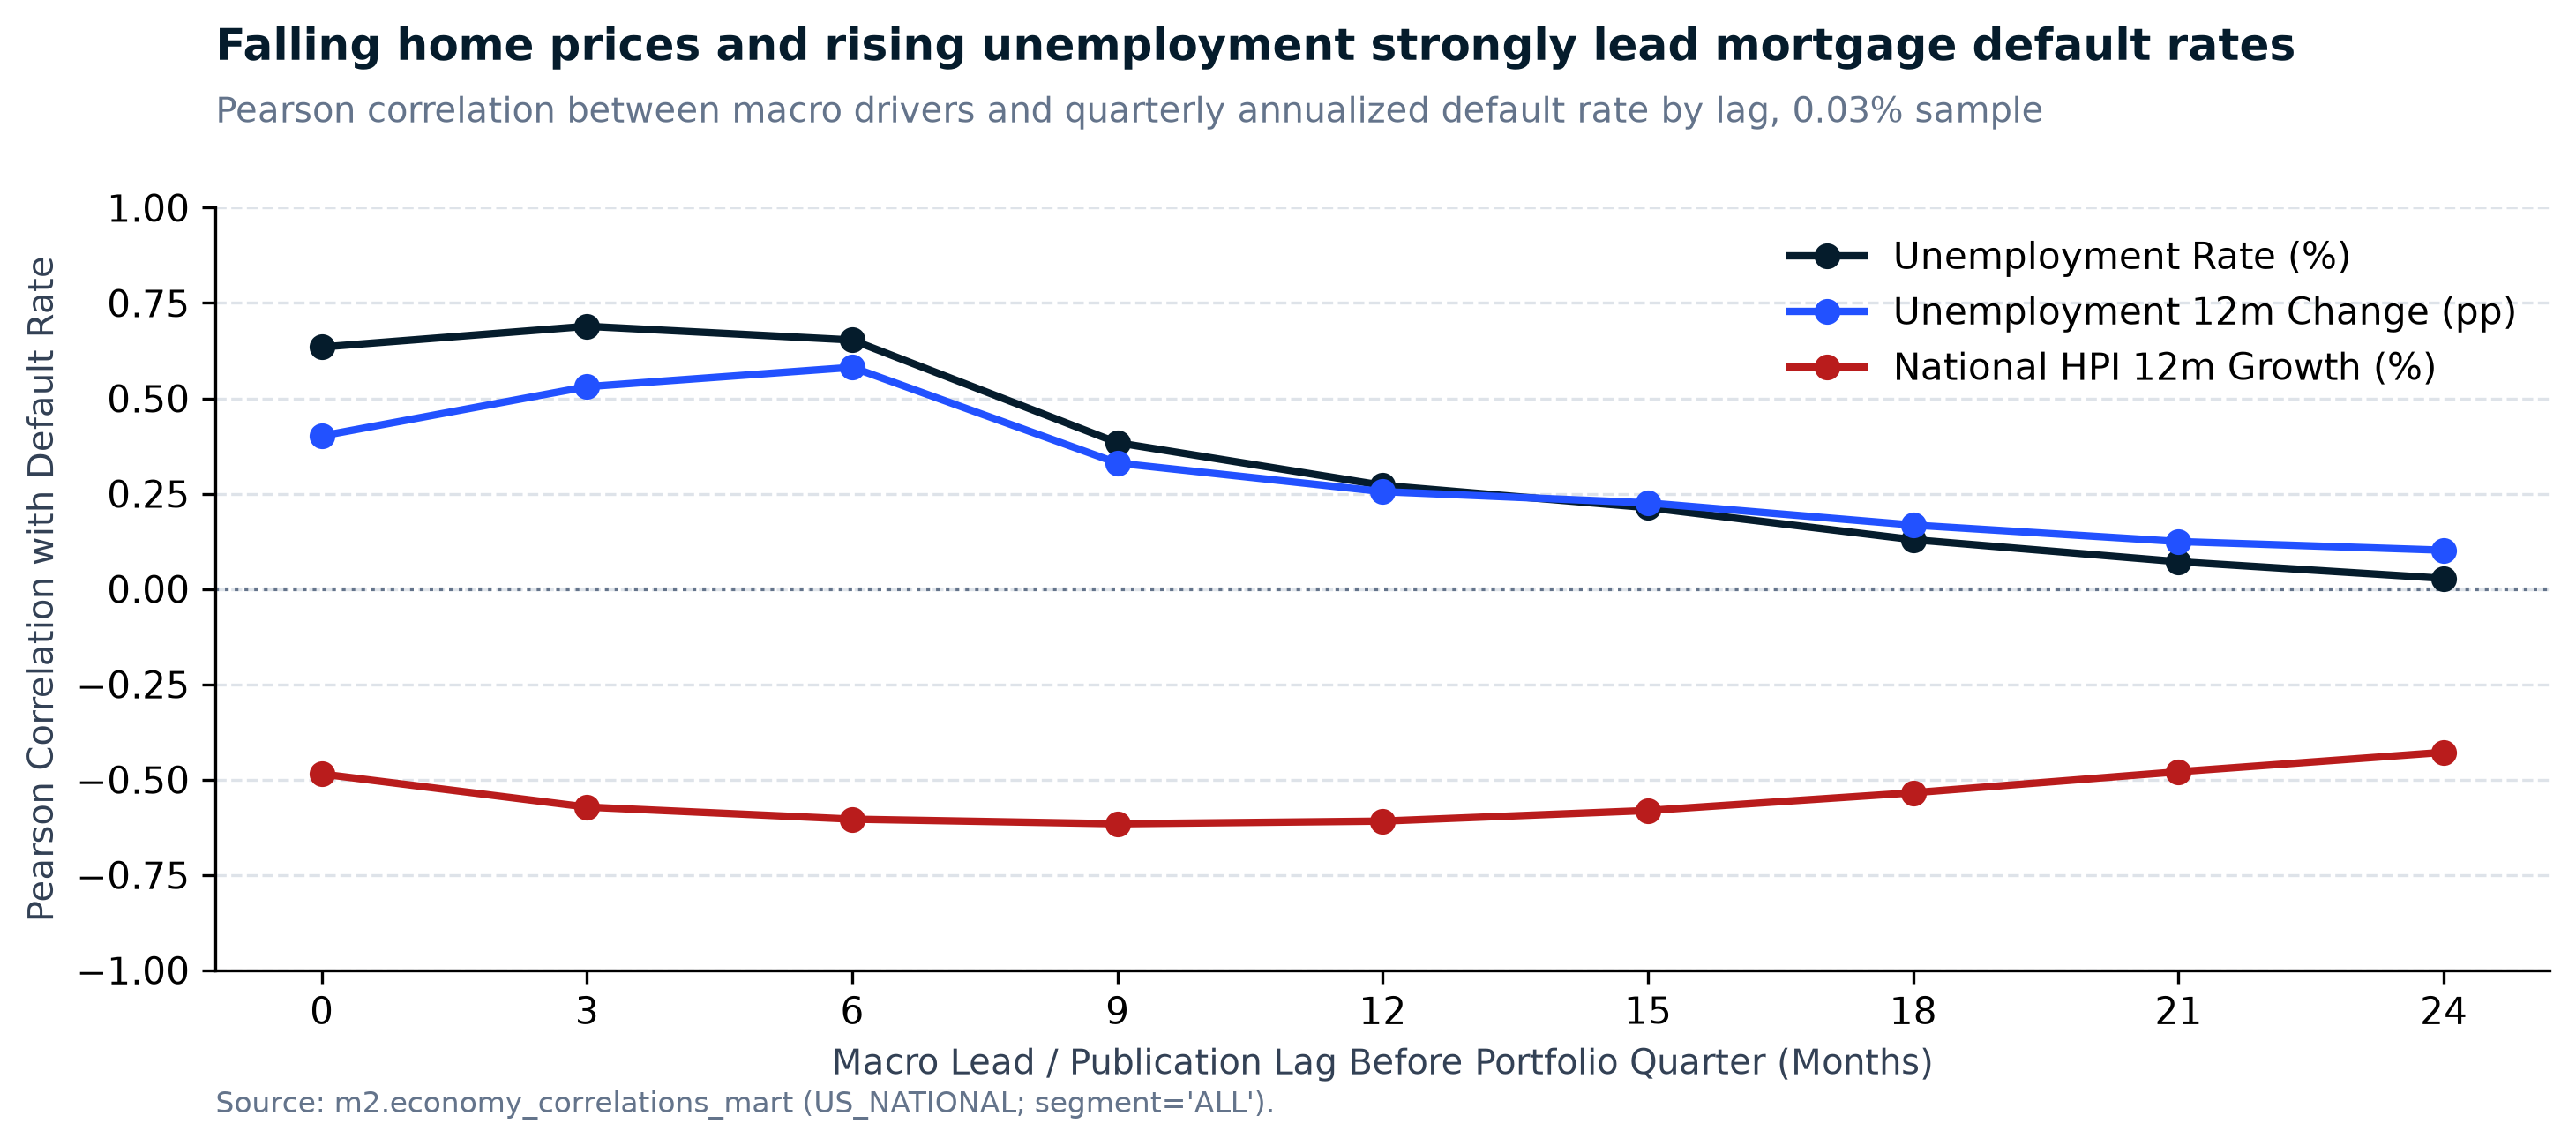

In [3]:
# Plot Pearson correlation vs publication lag (0 to 24 months) against annualized default rate
# Pivot m2.economy_correlations_mart across lag_months and render inline via BytesIO at 300 dpi
corr_df = con.execute("""
    SELECT lag_months, series_name, pearson_corr
    FROM m2.economy_correlations_mart
    WHERE rate_name = 'default_rate_ann' AND geography = 'US_NATIONAL'
      AND series_name IN ('unrate_pct', 'unrate_chg_12m', 'nat_hpi_chg_12m_pct')
    ORDER BY lag_months
""").fetchdf().pivot(index="lag_months", columns="series_name", values="pearson_corr")

fig, ax = plt.subplots(figsize=(9.8, 4.3), dpi=300, facecolor="#FFFFFF")
ax.set_facecolor("#FFFFFF")
for s_name, color, lbl in [
    ("unrate_pct", "#051C2C", "Unemployment Rate (%)"),
    ("unrate_chg_12m", "#2251FF", "Unemployment 12m Change (pp)"),
    ("nat_hpi_chg_12m_pct", "#B91C1C", "National HPI 12m Growth (%)"),
]:
    if s_name in corr_df.columns:
        ax.plot(corr_df.index, corr_df[s_name], marker="o", linewidth=2.0, color=color, label=lbl, zorder=3)
ax.axhline(0.0, color="#64748B", linewidth=1.0, linestyle=":")
ax.set_xticks([0, 3, 6, 9, 12, 15, 18, 21, 24])
ax.set_ylim(-1.0, 1.0)
ax.grid(axis="y", linestyle="--", alpha=0.3, color="#94A3B8", zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_xlabel("Macro Lead / Publication Lag Before Portfolio Quarter (Months)", fontsize=9.5, color="#334155")
ax.set_ylabel("Pearson Correlation with Default Rate", fontsize=9.5, color="#334155")
ax.legend(frameon=False, loc="best")
fig.text(0.07, 0.94, "Falling home prices and rising unemployment strongly lead mortgage default rates", fontsize=12, fontweight="bold", color="#051C2C")
fig.text(0.07, 0.885, "Pearson correlation between macro drivers and quarterly annualized default rate by lag, 0.03% sample", fontsize=9.5, color="#64748B")
fig.text(0.07, 0.015, "Source: m2.economy_correlations_mart (US_NATIONAL; segment='ALL').", fontsize=8, color="#64748B")
plt.subplots_adjust(left=0.07, right=0.97, top=0.81, bottom=0.14)
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=300, bbox_inches="tight", facecolor="#FFFFFF")
plt.close(fig)
display(Image(data=buf.getvalue()))

# Close the in-memory DuckDB connection cleanly
# Release the attached read-only sample DB handle
con.close()